# CS 839 HW1: Agent memory experiment (no memory, episodic, structured)

Runs the 12 tasks in `data/tasks.json` **in order** (T1 → T12) under three memory conditions and compares them.

- **No memory**: every task starts from scratch. Same requests as `hw1_no_memory.ipynb`.
- **Episodic**: after each task the episode (request, tool calls, answer, verdict) is stored; the 3 most similar past episodes are shown with the next request.
- **Structured**: after each task an LLM writer updates a compact list of rules, procedures, warnings and exceptions (at most 8 records, 150 words), which is shown with every request.

**Feedback is binary.** After each task the memory learns only whether the answer was judged CORRECT or INCORRECT, like a colleague saying "these numbers don't check out". It never sees the reference answer, the grader's failure label, `failure_conditions` or `reference_calls`.

Protocol (from the README): one run = T1 to T12 in order; memory is cleared at the start of each run; 5 runs per condition; conditions interleaved; no memory re-run alongside. Same model (`gpt-5.6-luna`) and tools in every condition, and the memory writer uses the same model.

Code: `utils/agent.py` (the agent loop from `hw1_no_memory.ipynb` plus a memory hook), `utils/memory.py` (the three conditions), `utils/experiment.py` (runs and saved traces), `utils/test_memory.py` (offline checks). Run this notebook from the repo root.

## 1. Setup

The API key is read from a `.env` file in this folder or any parent folder (`OPENAI_API_KEY`, optional `CS839_MODEL`). Otherwise it is entered with `getpass`. Never paste a key into a code cell or commit `.env`.

In [1]:
%pip install -q -r requirements.txt matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from utils.agent import compact_trace
from utils.experiment import CONDITIONS, load_env, load_spec, load_traces, make_client, run_all, spent_usd, trace_cost
from utils.grader import grade_canonical
from utils.memory import EPISODIC_HEADER, STRUCTURED_HEADER, WRITER_INSTRUCTIONS, render_records

env_found = load_env() is not None
MODEL = os.getenv("CS839_MODEL", "gpt-5.6-luna")
if not os.getenv("OPENAI_API_KEY"):
    import getpass
    entered_key = getpass.getpass("Paste your team's API key (hidden): ").strip()
    if entered_key:
        os.environ["OPENAI_API_KEY"] = entered_key

client = make_client() if os.getenv("OPENAI_API_KEY") else None
print(f"Model: {MODEL} | .env {'found' if env_found else 'not found'}")
print("API client ready." if client else "No key supplied. Saved runs can still be analyzed.")

Model: gpt-5.6-luna | .env found
API client ready.


## 2. Hypotheses (written and committed before any memory-condition run)

Baseline: no memory, 5 runs on Oct 6 (`runs/no_memory_20261006_121523.json`): T1 5/5, T2 3/5, T3 5/5, T4 5/5, T5 0/5, T6 0/5, T7 1/5, T8 5/5, T9 1/5, T10 5/5, T11 4/5, T12 2/5. Almost every miss comes from the default projection EPSG:3857.

**H1 (memory helps).** Structured memory will fix the area and density tasks that come after T2. T5, T6, T7 and T12 will each go from at most 2/5 without memory to at least 4/5, because after T2 the writer will store a rule to use `projection="EPSG:5070"` for area and density. Episodic memory will help less, at most 3/5 on average over T5–T7, because the agent must retrieve the T2 episode and re-derive the rule from a raw trace.

**H2 (memory hurts or has no effect).** Memory will not help on the two exceptions, and can hurt:
- T9 (Alaska–Maine distance): in at least 2 of 5 runs of each memory condition the agent will carry the area rule over to distance and use planar EPSG:5070 (5,801 km instead of the geodesic 5,350.4 km), so neither memory condition will beat no memory on T9 by more than one run.
- T8 (U.S. total): in at least 1 of 5 runs of a memory condition, the "states means the 50 states" lesson from T4–T7 will make the agent leave out DC (341,091,212), while no memory gets 5/5.
- T1, T3, T4, T10 (5/5 without memory): memory will not change accuracy; it will only add input tokens.

## 3. Tasks

`data/tasks.json` is the source of truth (questions, answer formats, reference answers, known mistakes). The order is T1 → T12.

In [3]:
SPEC = load_spec()
TASKS = {t["id"]: t for t in SPEC["tasks"]}
ORDER = [t["id"] for t in SPEC["tasks"]]

pd.set_option("display.max_colwidth", 140)
pd.DataFrame([{"id": t["id"], "type": t["type"], "rules": ", ".join(t["rules"]), "question": t["question"]}
              for t in SPEC["tasks"]]).set_index("id")

,type,rules,question
id,,,
T1,warm-up,,"Our annual report opens with the most populous state. Which state is it, and what was its population in 2025?"
T2,learn,B,A draft slide says the most populous state is also the largest state by area. Is that right? Give the area in km² of both states.
T3,warm-up,,For the Wisconsin state brief: how many states had more people than Wisconsin in 2025?
T4,learn,A,A federal pilot program is open only to states with fewer people than Wisconsin in 2025. How many states are eligible?
T5,reuse,B,A rural health program targets the 5 least densely populated states. List them with their densities in people per km².
T6,reuse,"A, B",A small-states grant covers the 5 states with the smallest area. List them with their areas in km².
T7,reuse,"A, B",A transit funding memo needs the 5 most densely populated states. List them with their densities in people per km².
T8,exception,A (exception),The report's headline figure is the population of the United States in the Census Bureau's 2025 estimates. What is it?
T9,exception,B (exception),A map caption needs the distance in km between the centroids of Alaska and Maine. What is it?


## 4. The memory conditions

| | Episodic | Structured |
|---|---|---|
| **Write** | After each task, store the episode as text: request, every tool call with its arguments and a truncated result, the final answer, and the verdict. No LLM call. | After each task, one writer call (same model) sees the current memory, the episode text, the verdict and the tool descriptions, and returns the full updated memory plus a change log. |
| **Retrieve** | Before each task, TF-IDF cosine (character 4-grams) between the new request and each stored episode; the top 3 are shown. Ties go to the most recent. | The whole memory is shown with every request (it is small). |
| **Update** | None: episodes are never edited. | The writer adds, revises, merges or deletes records. On a conflict it should narrow the old record and add an `exception`. |
| **Forget** | None within a run (at most 11 episodes). | Hard budget of 8 records and 150 words: one re-prompt if over budget, then the least supported records (fewest evidence entries) are cut. In the saved runs every over-budget reply was fixed by the re-prompt. |

Both memories are cleared at the start of each run. The exact text shown to the agent at each task is saved in the trace (`memory_shown`), and so is the memory after each update (`memory_after`).

In [4]:
print(EPISODIC_HEADER, "\n")
print(STRUCTURED_HEADER, "\n")
print("WRITER INSTRUCTIONS\n" + WRITER_INSTRUCTIONS.format(max_records=8, max_words=150))

PAST EPISODES: your own earlier attempts at related requests, each with the reviewer's verdict (CORRECT or INCORRECT; the reviewer gave no other feedback). They may or may not apply to the current request. 

MEMORY: lessons you recorded after earlier requests, based on whether a reviewer judged each answer CORRECT or INCORRECT. Apply a lesson only when its 'when' condition matches the current request. 

WRITER INSTRUCTIONS
You maintain the long-term memory of an analyst agent. The agent answers a sequence of short, different data requests using a fixed set of tools. After each request you see what the agent did and whether a reviewer judged the final answer CORRECT or INCORRECT. The reviewer gives no other feedback and never reveals the right answer.

Update the memory so that the agent does better on future, different requests.

Each memory record has:
- id: a short unique string such as "m1"
- type: "rule", "procedure", "warning" or "exception"
- when: the kind of request or tool use

## 5. Offline checks (no API credit)

The grader must pass every reference answer and label every known mistake, and `utils/test_memory.py` checks the memory code with a stub client, including that no forbidden field ever reaches the agent or the writer.

In [5]:
for t in SPEC["tasks"]:
    assert grade_canonical(t, t["answer"])["correct"], t["id"]
    for fc in t["failure_conditions"]:
        g = grade_canonical(t, fc["answer"])
        assert not g["correct"] and g["label"] == fc["cause"], (t["id"], g)
print("Grader OK on all 12 reference answers and",
      sum(len(t["failure_conditions"]) for t in SPEC["tasks"]), "known mistakes.\n")

out = subprocess.run([sys.executable, "utils/test_memory.py"], capture_output=True, text=True)
print(out.stdout[-2500:] or out.stderr[-2500:])

Grader OK on all 12 reference answers and 16 known mistakes.



ok   names: 'all' kept as is
ok   names: 50 states listed by what was left out
ok   names: short lists written out
ok   names: repeated names reported
ok   names: unknown names reported
ok   compact trace survives malformed tool arguments
ok   compact trace shows the projection argument
ok   compact trace: no step limit message when answered
ok   no memory: instructions identical to hw1_no_memory.ipynb
ok   no memory: user prompt is question + answer format
ok   stub task graded correct
ok   memory text appended after the instructions
     retrieved episodes: T1<--, T2<-T1, T3<-T1/T2, T4<-T3/T1/T2, T5<-T4/T3/T1, T6<-T2/T5/T4, T7<-T5/T1/T3, T8<-T1/T3/T4, T9<-T2/T7/T5, T10<-T4/T3/T7, T11<-T3/T4/T8, T12<-T7/T3/T4
ok   episodic: nothing to retrieve for T1
ok   episodic: at most k episodes, only earlier tasks
ok   episodic: T7 (most dense) retrieves T5 (least dense)
ok   episodic: T6 (smallest area) retrieves T2 (area)
ok   episodic: T12 (density) retrieves a density task
ok   episodic: T10

## 6. Helpers for reading traces

In [6]:
def show_trace(t, result_chars=200):
    verdict = "CORRECT" if t["correct"] else f"WRONG ({t['label']})"
    print(f"=== {t['condition']} | run {t['run']} | {t['task']} | {verdict} ===")
    if t.get("memory_shown"):
        print("Memory shown to the agent:")
        print("\n".join("  | " + line for line in t["memory_shown"].splitlines()))
    else:
        print("Memory shown to the agent: (none)")
    print(compact_trace(t["question"], t["calls"], t["final_answer"], result_chars))
    changes = (t.get("memory_update") or {}).get("changes") or []
    if changes:
        print("Memory changes after this task:")
        for c in changes:
            print("  -", c)
    print(f"tool calls {t['tool_calls']}, model calls {t['model_calls']}, "
          f"tokens in {t['input_tokens']:,}, out {t['output_tokens']:,}\n")


def sequence(traces, condition, run):
    return sorted((t for t in traces if t["condition"] == condition and t["run"] == run),
                  key=lambda t: ORDER.index(t["task"]))


def show_memory_timeline(traces, condition, run):
    for t in sequence(traces, condition, run):
        mark = "right" if t["correct"] else "WRONG"
        if condition == "structured":
            print(f"--- after {t['task']} ({mark}) ---")
            print(render_records(t["memory_after"]) or "(empty)")
            for c in t["memory_update"].get("changes", []):
                print("    change:", c)
        else:
            stored = ", ".join(f"{e['task']}:{'right' if e['correct'] else 'wrong'}" for e in t["memory_after"])
            print(f"{t['task']} ({mark}) | shown before this task: {t['retrieved'] or '-'} | stored after: {stored}")

## 7. Smoke test: T1–T4 with each memory

A cheap end-to-end check (two short sequences) before the full experiment: are the episodes and the writer's JSON sensible?

In [7]:
SMOKE_DIR = Path("runs/memory_smoke")
MAIN_DIR = Path("runs/memory_main")
BUDGET_USD = 3.00                      # the course limit is $5 per team; stop well before it
BUDGET_DIRS = (SMOKE_DIR, MAIN_DIR)

if client is not None:
    run_all(client, MODEL, SPEC, SMOKE_DIR, runs=[1], conditions=("episodic", "structured"),
            task_ids=["T1", "T2", "T3", "T4"], workers=2, budget_usd=BUDGET_USD, budget_dirs=BUDGET_DIRS)
smoke = load_traces(SMOKE_DIR)
for condition in ("episodic", "structured"):
    print(f"\n########## {condition} ##########")
    show_memory_timeline(smoke, condition, 1)

0 sequences to run in runs/memory_smoke (2 already saved)
done; spent so far $0.8289

########## episodic ##########
T1 (right) | shown before this task: - | stored after: T1:right
T2 (right) | shown before this task: ['T1'] | stored after: T1:right, T2:right
T3 (right) | shown before this task: ['T1', 'T2'] | stored after: T1:right, T2:right, T3:right
T4 (WRONG) | shown before this task: ['T3', 'T1', 'T2'] | stored after: T1:right, T2:right, T3:right, T4:wrong

########## structured ##########
--- after T1 (right) ---
- [m1 | procedure] When: Requests for the most populous region or state Do: Call get_population with names="all", order="desc", limit=1 (or a small limit), then report the top matching state and its population. (evidence: T1:right)
    change: added m1: use descending all-region population results to identify the most populous state
--- after T2 (WRONG) ---
- [m1 | procedure] When: Requests for the most populous region without a type qualifier Do: Call get_population wit

## 8. Full experiment: 5 runs × 3 conditions

Each (condition, run) is saved to `runs/memory_main/<condition>_runNN.json` as soon as it finishes, so re-running this cell resumes and never repeats a finished sequence. Sequences are queued run by run (run 1 of all three conditions, then run 2, …), so the conditions are interleaved in time.

The saved runs were made on Oct 11, 2026 (afternoon) from the command line with the final code (`utils/` as of commit `5a1a3d7`): `python -m utils.experiment --out runs/memory_main --runs 1-5 --workers 6`, then the same with `--runs 6-10` (two runs, six sequences, at a time). The cells below run the same function with the same settings; with everything saved they only report "0 sequences to run".

An earlier complete experiment with the same protocol was made in the morning with `utils/` as of `4aafee0`, before the review fixes. It is archived in `runs/archive_v1_4aafee0/` and compared in section 10 as a replication.

In [8]:
N_RUNS = 5
if client is not None:
    run_all(client, MODEL, SPEC, MAIN_DIR, runs=range(1, N_RUNS + 1), workers=6,
            budget_usd=BUDGET_USD, budget_dirs=BUDGET_DIRS)
print(f"Spent on the memory experiment so far: ${spent_usd(*BUDGET_DIRS):.3f}")

0 sequences to run in runs/memory_main (15 already saved)
done; spent so far $0.8289
Spent on the memory experiment so far: $0.829


## 9. Stability reruns

After runs 1–5 the surprising comparison was T9: no memory solved it in 4/5 runs, episodic memory in 1/5 and structured memory in 0/5. Structured memory was also ahead on T7 (3/5 vs 2/5) and T12 (3/5 vs 1/5). All three conditions were therefore run 5 more times (runs 6–10), the same protocol as in the first experiment. In runs 6–10 the structured gains on T7 (3/5 vs 1/5) and T12 (4/5 vs 1/5) kept their direction, the episodic deficit on T9 shrank (1/5 vs 2/5), and structured memory tied no memory on T9 (2/5 vs 2/5). None of these comparisons is significant within a batch of 5 runs (see the batch table in section 10). The results below pool all 10 runs, and section 10 also compares them with the first experiment.

In [9]:
STABILITY_RUNS = range(6, 11)
STABILITY_CONDITIONS = CONDITIONS
if client is not None:
    run_all(client, MODEL, SPEC, MAIN_DIR, runs=STABILITY_RUNS, conditions=STABILITY_CONDITIONS, workers=6,
            budget_usd=BUDGET_USD, budget_dirs=BUDGET_DIRS)
print(f"Spent on the memory experiment so far: ${spent_usd(*BUDGET_DIRS):.3f}")

0 sequences to run in runs/memory_main (15 already saved)
done; spent so far $0.8289
Spent on the memory experiment so far: $0.829


## 10. Results

In [10]:
traces = load_traces(MAIN_DIR)
baseline = json.loads(Path("runs/no_memory_20261006_121523.json").read_text())
for t in baseline:
    t["condition"] = "none (Oct 6)"


def row(t):
    upd = t.get("memory_update") or {}
    return {"condition": t["condition"], "run": t["run"], "task": t["task"], "correct": t["correct"],
            "label": t["label"], "tool_calls": t["tool_calls"], "model_calls": t["model_calls"],
            "input_tokens": t["input_tokens"], "output_tokens": t["output_tokens"],
            "memory_calls": upd.get("memory_calls", 0), "memory_input_tokens": upd.get("memory_input_tokens", 0),
            "memory_output_tokens": upd.get("memory_output_tokens", 0), "cost_usd": trace_cost(t)}


df = pd.DataFrame([row(t) for t in traces])
df_all = pd.concat([df, pd.DataFrame([row(t) for t in baseline])], ignore_index=True)
COLS = ["none (Oct 6)", *CONDITIONS]

counts = df_all.groupby(["task", "condition"])["correct"].agg(["sum", "count"])
table = (counts["sum"].astype(int).astype(str) + "/" + counts["count"].astype(str)).unstack()[COLS].reindex(ORDER)
table.insert(0, "type", [TASKS[i]["type"] for i in ORDER])
overall = df_all.groupby("condition")["correct"].agg(["sum", "count"])
table.loc["all"] = ["", *[f"{overall.loc[c, 'sum']}/{overall.loc[c, 'count']}" for c in COLS]]
Path("results").mkdir(exist_ok=True)
table.to_csv("results/summary_by_task.csv")
table

condition,type,none (Oct 6),none,episodic,structured
task,,,,,
T1,warm-up,5/5,10/10,10/10,10/10
T2,learn,3/5,1/10,3/10,1/10
T3,warm-up,5/5,10/10,10/10,10/10
T4,learn,5/5,10/10,9/10,10/10
T5,reuse,0/5,3/10,1/10,1/10
T6,reuse,0/5,1/10,3/10,2/10
T7,reuse,1/5,3/10,1/10,6/10
T8,exception,5/5,10/10,10/10,10/10
T9,exception,1/5,6/10,2/10,2/10


Two-sided Fisher exact tests of each memory condition against no memory (10 vs 10 runs per task, 120 vs 120 tasks overall). With 10 runs per condition only large differences can reach p < 0.05. The per-task p-values are nominal: the "Holm" columns correct them for the 24 per-task tests, and the second table splits the highlighted effects by batch.

In [11]:
import math


def fisher_p(a, n1, b, n2):
    # two-sided Fisher exact test for a/n1 vs b/n2 successes
    k, n = a + b, n1 + n2
    prob = lambda x: math.comb(n1, x) * math.comb(n2, k - x) / math.comb(n, k)
    observed = prob(a)
    return sum(prob(x) for x in range(max(0, k - n2), min(k, n1) + 1) if prob(x) <= observed * (1 + 1e-9))


k_n = df.groupby(["task", "condition"])["correct"].agg(["sum", "count"]).astype(int)
tot = df.groupby("condition")["correct"].agg(["sum", "count"]).astype(int)
sig = pd.DataFrame(
    {f"p, {c} vs none": [fisher_p(k_n.loc[(tid, c), "sum"], k_n.loc[(tid, c), "count"],
                                  k_n.loc[(tid, "none"), "sum"], k_n.loc[(tid, "none"), "count"]) for tid in ORDER]
     for c in ("episodic", "structured")}, index=ORDER)


def holm(pvalues):
    order = sorted(range(len(pvalues)), key=lambda i: pvalues[i])
    adjusted, running = [0.0] * len(pvalues), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(pvalues) - rank) * pvalues[i]))
        adjusted[i] = running
    return adjusted


raw_cols = list(sig.columns)
adjusted = holm(sig[raw_cols].to_numpy().T.ravel().tolist())
for j, c in enumerate(("episodic", "structured")):
    sig[f"Holm, {c}"] = adjusted[j * len(ORDER):(j + 1) * len(ORDER)]
sig.loc["all"] = [fisher_p(tot.loc[c, "sum"], tot.loc[c, "count"], tot.loc["none", "sum"], tot.loc["none", "count"])
                  for c in ("episodic", "structured")] + [None, None]
sig = sig.round(3)
sig.to_csv("results/fisher_by_task.csv")
sig

,"p, episodic vs none","p, structured vs none","Holm, episodic","Holm, structured"
T1,1.000,1.000,1.0,1.0
T2,0.582,1.000,1.0,1.0
T3,1.000,1.000,1.0,1.0
T4,1.000,1.000,1.0,1.0
T5,0.582,0.582,1.0,1.0
T6,0.582,1.000,1.0,1.0
T7,0.582,0.370,1.0,1.0
T8,1.000,1.000,1.0,1.0
T9,0.170,0.170,1.0,1.0
T10,1.000,1.000,1.0,1.0


In [12]:
# every task where a memory condition differs from no memory by at least 3 of the 10 runs
highlighted = [(tid, c) for tid in ORDER for c in ("episodic", "structured")
               if abs(k_n.loc[(tid, c), "sum"] - k_n.loc[(tid, "none"), "sum"]) >= 3]
batch_rows = []
for tid, c in highlighted:
    entry = {"comparison": f"{tid}: {c} vs none"}
    for name, in_batch in (("runs 1-5", df["run"] <= 5), ("runs 6-10", df["run"] > 5), ("all 10 runs", df["run"] > 0)):
        d = df[in_batch & (df["task"] == tid)]
        a, b = d[d["condition"] == c]["correct"], d[d["condition"] == "none"]["correct"]
        entry[name] = f"{a.sum()}/{len(a)} vs {b.sum()}/{len(b)}, p={fisher_p(int(a.sum()), len(a), int(b.sum()), len(b)):.3f}"
    batch_rows.append(entry)
pd.DataFrame(batch_rows).set_index("comparison")

,runs 1-5,runs 6-10,all 10 runs
comparison,,,
T7: structured vs none,"3/5 vs 2/5, p=1.000","3/5 vs 1/5, p=0.524","6/10 vs 3/10, p=0.370"
T9: episodic vs none,"1/5 vs 4/5, p=0.206","1/5 vs 2/5, p=1.000","2/10 vs 6/10, p=0.170"
T9: structured vs none,"0/5 vs 4/5, p=0.048","2/5 vs 2/5, p=1.000","2/10 vs 6/10, p=0.170"
T11: episodic vs none,"5/5 vs 3/5, p=0.444","5/5 vs 4/5, p=1.000","10/10 vs 7/10, p=0.211"
T11: structured vs none,"5/5 vs 3/5, p=0.444","5/5 vs 4/5, p=1.000","10/10 vs 7/10, p=0.211"
T12: structured vs none,"3/5 vs 1/5, p=0.524","4/5 vs 1/5, p=0.206","7/10 vs 2/10, p=0.070"


In [13]:
per_run = df.groupby(["condition", "run"]).agg(
    correct=("correct", "sum"), tool_calls=("tool_calls", "sum"), model_calls=("model_calls", "sum"),
    task_input_tokens=("input_tokens", "sum"), task_output_tokens=("output_tokens", "sum"),
    memory_calls=("memory_calls", "sum"), memory_input_tokens=("memory_input_tokens", "sum"),
    memory_output_tokens=("memory_output_tokens", "sum"), cost_usd=("cost_usd", "sum"))
cost_table = per_run.groupby("condition").mean().reindex(list(CONDITIONS))
cost_table = cost_table.round({c: (4 if c == "cost_usd" else 1) for c in cost_table.columns})
cost_table.insert(0, "runs", per_run.groupby("condition").size().reindex(list(CONDITIONS)))
cost_table.to_csv("results/cost_by_condition.csv")
print("Mean per run of 12 tasks. Total spent on this experiment (incl. smoke test): "
      f"${spent_usd(*BUDGET_DIRS):.3f}")
cost_table

Mean per run of 12 tasks. Total spent on this experiment (incl. smoke test): $0.829


,runs,correct,tool_calls,model_calls,task_input_tokens,task_output_tokens,memory_calls,memory_input_tokens,memory_output_tokens,cost_usd
condition,,,,,,,,,,
none,10,7.2,30.7,37.5,83168.4,3263.2,0.0,0.0,0.0,0.0205
episodic,10,7.1,28.0,35.1,92347.6,2940.8,0.0,0.0,0.0,0.0220
structured,10,7.9,28.2,35.9,86036.0,3300.2,13.3,40692.9,8016.1,0.0389


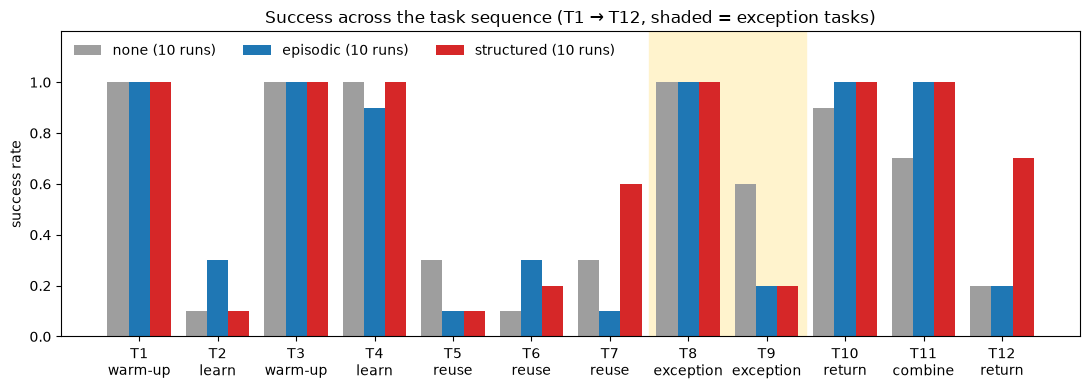

In [14]:
rates = df.pivot_table(index="task", columns="condition", values="correct", aggfunc="mean").reindex(ORDER)[list(CONDITIONS)]
n_runs = df.groupby("condition")["run"].nunique()
colors = {"none": "#9e9e9e", "episodic": "#1f77b4", "structured": "#d62728"}

fig, ax = plt.subplots(figsize=(11, 4))
width = 0.27
for i, c in enumerate(CONDITIONS):
    ax.bar([x + (i - 1) * width for x in range(len(ORDER))], rates[c], width,
           label=f"{c} ({n_runs[c]} runs)", color=colors[c])
    for x, v in enumerate(rates[c]):
        if v == 0:  # a zero-height bar is invisible: mark it
            ax.text(x + (i - 1) * width, 0.005, "0", ha="center", va="bottom", fontsize=8, color=colors[c])
for x, tid in enumerate(ORDER):
    if TASKS[tid]["type"] == "exception":
        ax.axvspan(x - 0.5, x + 0.5, color="#fff3cd", zorder=0)
ax.set_xticks(range(len(ORDER)))
ax.set_xticklabels([f"{tid}\n{TASKS[tid]['type']}" for tid in ORDER])
ax.set_ylabel("success rate")
ax.set_ylim(0, 1.2)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.set_title("Success across the task sequence (T1 → T12, shaded = exception tasks)")
ax.legend(loc="upper left", ncol=3, frameon=False)
fig.tight_layout()
Path("figures").mkdir(exist_ok=True)
fig.savefig("figures/success_by_task.png", dpi=200)
plt.show()

In [15]:
# Wrong answers by cause (grader labels; never shown to the agent or the memory)
wrong = df[~df["correct"]]
causes = pd.crosstab([wrong["task"], wrong["label"]], wrong["condition"]).reindex(columns=list(CONDITIONS), fill_value=0)
causes.loc[sorted(causes.index, key=lambda ix: (ORDER.index(ix[0]), ix[1]))]

condition                                                                                          none  \
task label                                                                                                
T2   Default projection EPSG:3857 (rule B). The yes/no part is still right.                           7   
     other                                                                                            2   
T4   Counted every row with a population, including DC and Puerto Rico (rule A).                      0   
T5   Default projection EPSG:3857 (rule B).                                                           7   
T6   Default projection EPSG:3857 (rule B).                                                           6   
     Right states, but areas from the default projection EPSG:3857 (rule B).                          1   
     other                                                                                            2   
T7   Default projection EPSG:3857 (rule B).                                                           7   
T9   Default planar distance in EPSG:3857.                                                            4   
T10  Included DC: rule A not applied, or the T8 exception carried over to a states-only question.     1   
T11  Default planar distance in EPSG:3857: distances inflated, states missed.                         3   
T12  Default projection EPSG:3857 for area (rule B not reapplied after T9).                           5   
     Used every row with a population, including DC and Puerto Rico (rule A).                         1   
     other                                                                                            2   

condition                                                                                          episodic  \
task label                                                                                                    
T2   Default projection EPSG:3857 (rule B). The yes/no part is still right.                               6   
     other                                                                                                1   
T4   Counted every row with a population, including DC and Puerto Rico (rule A).                          1   
T5   Default projection EPSG:3857 (rule B).                                                               9   
T6   Default projection EPSG:3857 (rule B).                                                               6   
     Right states, but areas from the default projection EPSG:3857 (rule B).                              0   
     other                                                                                                1   
T7   Default projection EPSG:3857 (rule B).                                                               9   
T9   Default planar distance in EPSG:3857.                                                                8   
T10  Included DC: rule A not applied, or the T8 exception carried over to a states-only question.         0   
T11  Default planar distance in EPSG:3857: distances inflated, states missed.                             0   
T12  Default projection EPSG:3857 for area (rule B not reapplied after T9).                               6   
     Used every row with a population, including DC and Puerto Rico (rule A).                             0   
     other                                                                                                2   

condition                                                                                          structured  
task label                                                                                                     
T2   Default projection EPSG:3857 (rule B). The yes/no part is still right.                                 3  
     other                                                                                                  6  
T4   Counted every row with a population, including DC and Pue

**Replication.** The first complete experiment (Oct 11 morning, `utils/` as of `4aafee0`, before the review fixes) is archived in `runs/archive_v1_4aafee0/`. It used the same protocol, tasks, prompts and model, so the two experiments are independent repeats. The first table puts them side by side; the second pools them (20 runs per condition) with nominal and Holm-corrected Fisher tests.

In [16]:
V1_DIR = Path("runs/archive_v1_4aafee0/memory_main")
df_v1 = pd.DataFrame([row(t) for t in load_traces(V1_DIR)])


def x_of_n(d):
    k = d.groupby(["task", "condition"])["correct"].agg(["sum", "count"])
    out = (k["sum"].astype(int).astype(str) + "/" + k["count"].astype(str)).unstack()[list(CONDITIONS)].reindex(ORDER)
    o = d.groupby("condition")["correct"].agg(["sum", "count"])
    out.loc["all"] = [f"{o.loc[c, 'sum']}/{o.loc[c, 'count']}" for c in CONDITIONS]
    return out


replication = pd.concat({"first experiment (4aafee0)": x_of_n(df_v1), "this experiment (final code)": x_of_n(df)}, axis=1)
replication.to_csv("results/replication_by_task.csv")
replication

first experiment (4aafee0)                      \
condition                       none episodic structured   
task                                                       
T1                             10/10    10/10      10/10   
T2                              1/10     2/10       0/10   
T3                             10/10    10/10       9/10   
T4                             10/10     8/10      10/10   
T5                              6/10     0/10       0/10   
T6                              1/10     1/10       2/10   
T7                              0/10     0/10       5/10   
T8                             10/10    10/10      10/10   
T9                              4/10     1/10       2/10   
T10                             9/10    10/10      10/10   
T11                             8/10     9/10      10/10   
T12                             2/10     1/10       6/10   
all                           71/120   62/120     74/120   

          this experiment (final code)                      
condition                         none episodic structured  
task                                                        
T1                               10/10    10/10      10/10  
T2                                1/10     3/10       1/10  
T3                               10/10    10/10      10/10  
T4                               10/10     9/10      10/10  
T5                                3/10     1/10       1/10  
T6                                1/10     3/10       2/10  
T7                                3/10     1/10       6/10  
T8                               10/10    10/10      10/10  
T9                                6/10     2/10       2/10  
T10                               9/10    10/10      10/10  
T11                               7/10    10/10      10/10  
T12                               2/10     2/10       7/10  
all                             72/120   71/120     79/120

In [17]:
both = pd.concat([df_v1, df], ignore_index=True)
kb = both.groupby(["task", "condition"])["correct"].agg(["sum", "count"]).astype(int)
pooled = pd.DataFrame({c: [f"{kb.loc[(tid, c), 'sum']}/{kb.loc[(tid, c), 'count']}" for tid in ORDER] for c in CONDITIONS},
                      index=ORDER)
pooled_p = {c: [fisher_p(kb.loc[(tid, c), "sum"], kb.loc[(tid, c), "count"],
                         kb.loc[(tid, "none"), "sum"], kb.loc[(tid, "none"), "count"]) for tid in ORDER]
            for c in ("episodic", "structured")}
pooled_holm = holm(pooled_p["episodic"] + pooled_p["structured"])
for j, c in enumerate(("episodic", "structured")):
    pooled[f"p, {c}"] = [round(p, 3) for p in pooled_p[c]]
    pooled[f"Holm, {c}"] = [round(p, 3) for p in pooled_holm[j * len(ORDER):(j + 1) * len(ORDER)]]
pooled.to_csv("results/pooled_20_runs.csv")
pooled

,none,episodic,structured,"p, episodic","Holm, episodic","p, structured","Holm, structured"
T1,20/20,20/20,20/20,1.000,1.000,1.000,1.000
T2,2/20,5/20,1/20,0.407,1.000,1.000,1.000
T3,20/20,20/20,19/20,1.000,1.000,1.000,1.000
T4,20/20,17/20,20/20,0.231,1.000,1.000,1.000
T5,9/20,1/20,1/20,0.008,0.201,0.008,0.201
T6,2/20,4/20,4/20,0.661,1.000,0.661,1.000
T7,3/20,1/20,11/20,0.605,1.000,0.019,0.393
T8,20/20,20/20,20/20,1.000,1.000,1.000,1.000
T9,10/20,3/20,4/20,0.041,0.815,0.096,1.000
T10,18/20,20/20,20/20,0.487,1.000,0.487,1.000


Did the stored projection rule matter? Every structured-memory record that mentions EPSG:5070 or EPSG:3857 (113 distinct records over both experiments) was labelled by hand in `results/projection_rule_labels.json`: recommends EPSG:5070, keeps the EPSG:3857 default, only asks for consistency, or is a distance rule. Keyword matching was not reliable: "use EPSG:3857 consistently; use EPSG:5070 only when requested" mentions EPSG:5070 but keeps the default. The table gives success on the area and density tasks by the projection rule in the memory shown at that task. The timeline gives, for each run of this experiment, the outcome of T1–T12 (1 = right) and the rule shown at each task (5 = EPSG:5070, 3 = EPSG:3857, b = both, - = none).

In [18]:
LABELS = {x["do"]: x["label"] for x in json.loads(Path("results/projection_rule_labels.json").read_text())["labels"]}


def rule_state(records):
    labels = {LABELS[r["do"]] for r in records if "5070" in r["do"] or "3857" in r["do"]}  # KeyError: unlabelled record
    if "5070" in labels:
        return "EPSG:5070 and EPSG:3857" if "3857" in labels else "EPSG:5070"
    return "EPSG:3857" if "3857" in labels else "no projection rule"


def shown_states(trs):
    rows = []
    for run in sorted({t["run"] for t in trs if t["condition"] == "structured"}):
        prev = []
        for t in sequence(trs, "structured", run):
            rows.append({"run": run, "task": t["task"], "rule shown": rule_state(prev), "correct": t["correct"]})
            prev = t["memory_after"]
    return pd.DataFrame(rows)


parts = []
for name, trs in (("this experiment", traces), ("first experiment", load_traces(V1_DIR))):
    s = shown_states(trs)
    s = s[s["task"].isin(["T5", "T6", "T7", "T12"])]
    k = s.groupby(["task", "rule shown"])["correct"].agg(["sum", "count"])
    parts.append((k["sum"].astype(str) + "/" + k["count"].astype(str)).rename(name))
rules = pd.concat(parts, axis=1).fillna("-")
print(rules.reindex(sorted(rules.index, key=lambda ix: (ORDER.index(ix[0]), ix[1]))), "\n")

codes = {"EPSG:5070": "5", "EPSG:3857": "3", "EPSG:5070 and EPSG:3857": "b", "no projection rule": "-"}
for run, g in shown_states(traces).groupby("run"):
    print(f"run {run:>2}  outcomes {''.join('1' if c else '.' for c in g['correct'])}"
          f"  rule shown {''.join(codes[x] for x in g['rule shown'])}")

                             this experiment first experiment
task rule shown                                              
T5   EPSG:3857                           0/2              0/3
     EPSG:5070                           0/1                -
     no projection rule                  1/7              0/7
T6   EPSG:3857                           0/3              1/2
     EPSG:5070                           1/2              1/4
     EPSG:5070 and EPSG:3857             0/1                -
     no projection rule                  1/4              0/4
T7   EPSG:3857                           0/1              0/2
     EPSG:5070                           5/6              5/7
     EPSG:5070 and EPSG:3857             0/1                -
     no projection rule                  1/2              0/1
T12  EPSG:3857                           0/1                -
     EPSG:5070                           5/6              6/9
     EPSG:5070 and EPSG:3857             0/1                -
     no 

## 11. Memory after each task (run 1 of each memory condition)

For episodic memory: which past episodes were shown before each task, and what was stored after it. For structured memory: the full memory after each update, with the writer's change log.

In [19]:
for condition in ("episodic", "structured"):
    print(f"\n########## {condition}, run 1 ##########")
    show_memory_timeline(traces, condition, 1)


########## episodic, run 1 ##########
T1 (right) | shown before this task: - | stored after: T1:right
T2 (WRONG) | shown before this task: ['T1'] | stored after: T1:right, T2:wrong
T3 (right) | shown before this task: ['T1', 'T2'] | stored after: T1:right, T2:wrong, T3:right
T4 (right) | shown before this task: ['T3', 'T1', 'T2'] | stored after: T1:right, T2:wrong, T3:right, T4:right
T5 (WRONG) | shown before this task: ['T4', 'T3', 'T1'] | stored after: T1:right, T2:wrong, T3:right, T4:right, T5:wrong
T6 (WRONG) | shown before this task: ['T2', 'T5', 'T4'] | stored after: T1:right, T2:wrong, T3:right, T4:right, T5:wrong, T6:wrong
T7 (WRONG) | shown before this task: ['T5', 'T1', 'T3'] | stored after: T1:right, T2:wrong, T3:right, T4:right, T5:wrong, T6:wrong, T7:wrong
T8 (right) | shown before this task: ['T1', 'T3', 'T4'] | stored after: T1:right, T2:wrong, T3:right, T4:right, T5:wrong, T6:wrong, T7:wrong, T8:right
T9 (WRONG) | shown before this task: ['T2', 'T5', 'T7'] | stored aft

## 12. Final structured memory (every run)

In [20]:
for run in sorted(df[df["condition"] == "structured"]["run"].unique()):
    last = sequence(traces, "structured", run)[-1]
    acc = sum(t["correct"] for t in sequence(traces, "structured", run))
    print(f"--- structured run {run} ({acc}/12 correct) ---")
    print(render_records(last["memory_after"]), "\n")

--- structured run 1 (8/12 correct) ---
- [m1 | procedure] When: Most/least populous region Do: Call get_population(names="all", order=asc/desc, limit=1). (evidence: T1:right)
- [m2 | warning] When: Area comparisons/rankings Do: Use one explicit projection for all get_area calls; never mix EPSG:3857 and EPSG:5070. (evidence: T2:wrong, T6:right)
- [m3 | procedure] When: Counting regions above/below a benchmark Do: Get benchmark; filter get_population(names="all", greater_than/less_than=value); inequalities are strict. (evidence: T3:right, T4:right)
- [m4 | procedure] When: U.S.-states-only requests Do: Construct and verify the exact 50 states from list_regions, excluding DC/territories, then rank. (evidence: T4:right, T5:wrong, T6:right, T7:wrong, T10:right, T11:right)
- [m5 | procedure] When: U.S. population requests Do: get_population(names="all"); subtract Puerto Rico if included. (evidence: T8:right)
- [m6 | procedure] When: Unspecified centroid-distance requests Do: Use method="geo

## 13. Two trajectories

Candidates are found automatically; the two shown below are discussed in the next cell.

In [21]:
def find(condition, task, correct):
    return [t for t in traces if t["condition"] == condition and t["task"] == task and t["correct"] == correct]


print("Memory helped (higher success rate than no memory on the same task):")
for tid in ORDER:
    for c in ("episodic", "structured"):
        if rates.loc[tid, c] > rates.loc[tid, "none"]:
            print(f"  {tid} {c}: {rates.loc[tid, c]:.0%} vs none {rates.loc[tid, 'none']:.0%}; "
                  f"right in runs {[t['run'] for t in find(c, tid, True)]}")
print("\nMemory misled (memory wrong where no memory is mostly right, or a memory-induced label):")
INDUCED = ("Excluded DC", "Planar distance in EPSG:5070", "T8 exception carried over")
for t in traces:
    if t["condition"] != "none" and not t["correct"]:
        base_rate = rates.loc[t["task"], "none"]
        if base_rate >= 0.6 or any(s in (t["label"] or "") for s in INDUCED):
            print(f"  {t['task']} {t['condition']} run {t['run']}: {t['label']} (none: {base_rate:.0%} right)")

Memory helped (higher success rate than no memory on the same task):
  T2 episodic: 30% vs none 10%; right in runs [4, 8, 9]
  T6 episodic: 30% vs none 10%; right in runs [4, 8, 9]
  T6 structured: 20% vs none 10%; right in runs [1, 4]
  T7 structured: 60% vs none 30%; right in runs [3, 4, 5, 6, 7, 8]
  T10 episodic: 100% vs none 90%; right in runs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  T10 structured: 100% vs none 90%; right in runs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  T11 episodic: 100% vs none 70%; right in runs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  T11 structured: 100% vs none 70%; right in runs [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
  T12 structured: 70% vs none 20%; right in runs [1, 3, 4, 6, 7, 8, 9]

Memory misled (memory wrong where no memory is mostly right, or a memory-induced label):
  T9 episodic run 1: Default planar distance in EPSG:3857. (none: 60% right)
  T9 episodic run 2: Default planar distance in EPSG:3857. (none: 60% right)
  T9 episodic run 3: Default planar distance in EPSG:3857.

In [22]:
HELPED = ("structured", 4, "T6")
MISLED = ("structured", 10, "T7")
for condition, run, task in (HELPED, MISLED):
    show_trace(next(t for t in traces if (t["condition"], t["run"], t["task"]) == (condition, run, task)))

=== structured | run 4 | T6 | CORRECT ===
Memory shown to the agent:
  | MEMORY: lessons you recorded after earlier requests, based on whether a reviewer judged each answer CORRECT or INCORRECT. Apply a lesson only when its 'when' condition matches the current request.
  | - [m1 | procedure] When: Requests asking for the most or least populous region/state Do: Use get_population(names="all", order="desc" or "asc", limit=1); report the returned name and population, without substituting another year. (evidence: T1:right)
  | - [m2 | warning] When: Requests explicitly limited to U.S. states while the dataset also contains other areas Do: Do not assume an all-rows result answers a state-only question; use list_regions and restrict comparisons to recognized state names before ranking, when the tool data permit. (evidence: T2:wrong, T3:right, T4:right)
  | - [m3 | procedure] When: Counting states with more or fewer people than a named state Do: Get the named state's population, query get_pop

**Memory helped: structured, run 4, T6 (the 5 states with the smallest area).** Without memory T6 failed in 9/10 runs, 7 of them with EPSG:3857 areas: the default projection inflates area, and in 6 runs it even put Hawaii into the top 5. In structured run 4 the T2 failure taught nothing about projections (the writer stored a lesson about separating states from other rows). The lesson came from the next failure. After T5 (least dense, wrong with the default) the writer added *m4 — when: "Requests comparing area or population density across states or regions without a stated projection"; do: "Likely use get_density or get_area with projection="EPSG:5070" (equal-area Albers), rather than relying on the EPSG:3857 default; restrict to the requested state/region universe before ranking."* At T6 the agent followed m4, called `get_area(..., projection="EPSG:5070")`, and was right; the writer added T6:right as evidence, and the same rule then got T7 and T12 right (evidence T5:wrong, T6:right, T7:right, T12:right). Across both experiments, T7 was right in 10/13 structured runs whose memory held an EPSG:5070 rule and no conflicting EPSG:3857 rule, and in 1/7 runs otherwise (section 10).

**Memory misled: structured, run 10, T7 (the 5 most densely populated states).** Here the writer turned failures into the wrong rule. At T6 the agent ranked with EPSG:5070 but reported EPSG:3857 areas. The writer saw the inconsistency but fixed it in the wrong direction, storing *m4: "Use the default EPSG:3857 consistently for both ranking and reported areas. Do not rank with EPSG:5070 and report EPSG:3857 values."* At T7 the agent followed m4, used the default projection and was wrong again; the writer then strengthened the rule to *"Use EPSG:3857, the tool default, consistently for retrieval, ranking, and reported values; use EPSG:5070 only when requested"*, citing T6:wrong and T7:wrong as its evidence. At T12 the agent passed EPSG:3857 explicitly and failed once more, and the writer blamed manual counting instead. With right/wrong feedback alone the writer could not tell which part of its diagnosis was wrong, and it never dropped a rule whose only evidence was failures. Runs 3 and 6 stored "keep the default EPSG:3857" right after T2.

Episodic memory misled through a lucky success, as in the first experiment. In episodic run 4, T4 retrieved the T3 episode (judged CORRECT), which used `get_population(names="all", greater_than=<Wisconsin>)`. The agent reused it with `less_than` and counted DC and Puerto Rico (31 instead of 29). T3's procedure was only right because DC and Puerto Rico have fewer people than Wisconsin. The same failure happened in episodic run 3 of the first experiment.

## 14. Findings

- **Overall (this experiment, 10 runs per condition):** no memory 72/120 (60%), episodic 71/120 (59%), structured 79/120 (66%). Neither memory condition differs significantly from no memory (Fisher exact p = 1.0 and 0.42). Mean cost per run of 12 tasks: $0.0205, $0.0220 and $0.0389; the structured writer adds about 3,400 input and 670 output tokens per task. This experiment cost $0.83 including its smoke test; with the first experiment ($0.86) the total is $1.69.
- **Replication.** The first experiment gave 71, 62 and 74 out of 120, and both show the same pattern: structured memory gains on the later area and density tasks (T7, T12) and on T11, and both memories do worse than no memory on T9. Pooled over 20 runs per condition: T7 3/20 → 11/20 and T12 4/20 → 13/20 with structured memory (nominal p = 0.019 and 0.010); T9 10/20 → 3/20 with episodic and 4/20 with structured memory (p = 0.041 and 0.096). The first experiment's T5 drop (6/10 → 0/10) was smaller here (3/10 → 1/10); pooled, 9/20 → 1/20 for both memories (p = 0.008). After a Holm correction for the 24 per-task tests none of these is significant (smallest 0.20), so the pattern is consistent but not established.
- **H1 is not supported as stated.** Structured memory did not fix the first reuse tasks (T5 1/10 and T6 2/10, against 3/10 and 1/10 without memory). It improved the later ones, T7 (3/10 → 6/10) and T12 (2/10 → 7/10), but not to the predicted 4/5. The predicted mechanism was wrong: across both experiments, in none of the 19 runs where T2 failed did the writer store an EPSG:5070 rule after T2, and 5 of them stored the opposite ("keep the default EPSG:3857"). The one run that answered T2 correctly (run 8 here) stored the right procedure at once. Otherwise a rule recommending EPSG:5070 appeared only after one or two further area or density failures here (6 of the other 9 runs; never in runs 1, 3 and 10) and after one to three in the first experiment (9 of 10 runs). Episodic memory never learned the rule (T5–T7: 1/10, 3/10, 1/10): retrieval never showed the T2 episode at T5 or T7, and showing it at T6 (all 10 runs) helped little (3/10).
- **H2 is partly supported.** Memory did not help on T9, it hurt: no memory 6/10, episodic 2/10, structured 2/10 (first experiment 4/10, 1/10, 2/10). But the predicted mechanism did not occur: every T9 failure, in every condition of both experiments, used the default planar EPSG:3857, never planar EPSG:5070. The structured memory said nothing about distance before T9 (0/10 runs); the difference is whether the agent chose `method="geodesic"` on its own (6/10 runs without memory, 2/10 with either memory). T8 was 10/10 in every condition of both experiments, so the 50-states lesson never removed DC. On T1, T3, T4 and T10 every condition stayed at 9/10 or better, while episodic memory added about 10% input tokens per task on these four tasks (11% over all twelve).
- **Evidence of learning:** within structured runs, success on the later area and density tasks follows a failure that was written into memory as an EPSG:5070 rule, and depends on the rule being there. Across both experiments T7 was right in 10/13 runs whose memory held an EPSG:5070 rule and no conflicting EPSG:3857 rule, and in 1/7 runs otherwise (T12: 11/15 vs 2/5). The geodesic exception was learned from the T9 failure and reused: at T11 every structured memory said to use geodesic distance, and structured T11 was 10/10 in both experiments (no memory 7/10 and 8/10). Episodic T11 was also 10/10 here, but its retrieval never showed the T9 episode, so that gain did not come from the T9 lesson.
- **Retrieved but not applied:** in run 8 the writer stored the right procedure after the correct T2 but scoped it to "comparing largest area with another ranked state"; T5 and T6 then used the default projection and failed. In the first experiment's run 1, a rule stored for density only was likewise not applied to an area ranking.
- **What should have been updated or forgotten:** in run 10 the writer kept "use the default EPSG:3857" while the only evidence for it was failures (T6:wrong, T7:wrong). A rule should be dropped or reversed when the tasks that followed it fail, and competing diagnoses should be kept, marked uncertain, until a later task decides between them.
- **Caveats:** 10 runs per condition per experiment detect only large effects, and all p-values above are nominal. The no-memory baseline itself moved between the experiments with identical prompts (T5 6/10 → 3/10, T7 0/10 → 3/10, T9 4/10 → 6/10), so effects are measured within an experiment, where the conditions were interleaved. Grader labels for wrong answers are heuristic.
- **What to change in a second version:** binary feedback leaves the writer guessing the cause, so a one-line reviewer note or the expected value would make credit assignment possible. Episodic retrieval matched only the wording of the new request against the stored episodes (request, calls and answer), and T5's request ("least densely populated") shares few words with the T2 episode, so T2 was never retrieved for T5. Embedding-based retrieval, or always showing the most recent INCORRECT episodes, would surface it.